# Interference: H versus SX

Notebook 04 showed that $|+\rangle$ and $|-\rangle$ give the same Z-basis
counts, yet one more $H$ sends them to opposite, certain results. In that
calculation some amplitudes added and others canceled. This notebook makes the
adding and canceling the main subject.

We compare two gates that both turn $|0\rangle$ into a 50/50 state: the
Hadamard gate $H$, and a new gate, the square root of NOT. One application of
either looks the same in the counts. Two applications give opposite answers.
Why? And how can a measurement tell the two one-gate states apart directly?

## Before you start

This notebook assumes:

- [Notebook 00](00_Bits_and_Basis_States.ipynb): the scatter rule for
  comparing a measured fraction with its ideal value.
- [Notebook 01](01_One_Bit_Operators.ipynb): $X$, $Z$, $X^2 = I$, and the
  Z-basis measurement.
- [Notebook 02](02_Reversible_Logic.ipynb): permutation matrices.
- [Notebook 04](04_Amplitudes_and_Phase.ipynb): amplitudes and the Born rule,
  the conjugate transpose and its reverse-order rule
  $(AB)^\dagger = B^\dagger A^\dagger$, unitary operators, overlap, $H$, $S$
  and $S^\dagger$, the states $|\pm\rangle$ and $|{\pm i}\rangle$ and their
  places on the Bloch sphere ($\pm x$ and $\pm y$), global and relative phase,
  `Statevector`, and the barrier.
- [Notebook 05](05_Rotation_From_Outer_Product.ipynb): the preparation
  operator $V_s = |s\rangle\langle 0| + |s_\perp\rangle\langle 1|$, which takes
  $|0\rangle$ to $|s\rangle$ and $|1\rangle$ to $|s_\perp\rangle$, and its
  inverse $V_s^\dagger$.

Quick check:

1. What is $H|-\rangle$?
2. What is $(1+i)(1-i)$?
3. What does $S^\dagger$ do to the amplitude of $|1\rangle$?

Answers: $|1\rangle$; $2$; it multiplies it by $-i$.

After this notebook you will be able to:

1. Predict the result of applying $H$ twice, or the square root of NOT twice,
   by adding amplitudes step by step.
2. Explain how two states with identical Z-basis counts can be different
   states.
3. Build a circuit that tells $|+\rangle$ from $|-\rangle$, or $|{+i}\rangle$
   from $|{-i}\rangle$, with a single measurement.

## Setup

The same setup as Notebook 00, plus the Qiskit classes used below.

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.circuit.library import SXGate
from qiskit.quantum_info import Operator, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# Aer, and IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit
    precision=0.02,              # used from Notebook 09 on
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## The square root of NOT

$X$ flips a bit. Is there a gate that does half of a flip, so that applying it
twice gives $X$? No classical reversible gate can. A reversible gate on one
bit is a $2\times2$ permutation matrix (Notebook 02), and there are only two:
$I$ and $X$. Both square to the identity, $I^2 = I$ and $X^2 = I$, so neither
squares to $X$. With complex coefficients (Notebook 04) there is such a gate.

Try a combination of the two operators we have, $c_0 I + c_1 X$, and require
its square to be $X$. Using $X^2 = I$,

$$(c_0 I + c_1 X)^2 = (c_0^2 + c_1^2)\,I + 2c_0c_1\,X ,$$

so we need $c_0^2 + c_1^2 = 0$ and $2c_0c_1 = 1$. The choice
$c_0 = \tfrac{1+i}{2}$, $c_1 = \tfrac{1-i}{2}$ works: $c_0^2 = \tfrac{2i}{4} = \tfrac{i}{2}$
and $c_1^2 = \tfrac{-2i}{4} = -\tfrac{i}{2}$ add to 0, and
$2c_0c_1 = \tfrac{2(1+i)(1-i)}{4} = \tfrac{2\cdot 2}{4} = 1$.

The *square root of NOT*, written $\sqrt{X}$ and called `SX` in Qiskit, is

$$\sqrt{X} = \frac{1+i}{2}\,I + \frac{1-i}{2}\,X = \frac12\begin{pmatrix}1+i & 1-i\\ 1-i & 1+i\end{pmatrix},\qquad \sqrt{X}\sqrt{X} = X .$$

In words: a gate that, applied twice, flips the bit. It is unitary (the code
below checks), and it is one of the native gates of IBM hardware.

In [2]:
I, X, Z = np.eye(2), np.array([[0, 1], [1, 0]]), np.diag([1, -1])
sx = (1 + 1j) / 2 * I + (1 - 1j) / 2 * X
h = (X + Z) / np.sqrt(2)

print("SX =\n", sx)
print("matches Qiskit's SXGate:", np.allclose(sx, Operator(SXGate()).data))
print("SX unitary:", np.allclose(sx.conj().T @ sx, I))
print("SX @ SX =\n", sx @ sx)
print("H @ H =\n", np.round(h @ h, 3) + 0)   # + 0 hides -0.0

SX =
 [[0.5+0.5j 0.5-0.5j]
 [0.5-0.5j 0.5+0.5j]]
matches Qiskit's SXGate: True
SX unitary: True
SX @ SX =
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
H @ H =
 [[1. 0.]
 [0. 1.]]


### Example 1: $\sqrt{X}|0\rangle$ and where it sits

**Problem.** Compute $\sqrt{X}|0\rangle$, its Z-basis probabilities, and which
named state of Notebook 04 it equals, up to a global phase.

**Plan.** Read the first column of the matrix, apply the Born rule, then
factor out the amplitude of $|0\rangle$ to expose the relative phase.

**Solution.**

**Subgoal 1: the state and its probabilities.**

1. $\sqrt{X}|0\rangle$ is the first column:
   $\tfrac12\big((1+i)|0\rangle + (1-i)|1\rangle\big)$.
2. Born rule: $P(0) = \tfrac{|1+i|^2}{4} = \tfrac{(1+i)(1-i)}{4} = \tfrac{2}{4} = \tfrac12$,
   and in the same way $P(1) = \tfrac{|1-i|^2}{4} = \tfrac12$.

**Subgoal 2: the relative phase.**

3. Factor out the amplitude of $|0\rangle$:
   $\tfrac{1+i}{2}\big(|0\rangle + \tfrac{1-i}{1+i}|1\rangle\big)$.
4. Simplify the ratio by multiplying top and bottom by $1-i$:
   $\tfrac{(1-i)^2}{(1+i)(1-i)} = \tfrac{1 - 2i + i^2}{2} = \tfrac{-2i}{2} = -i$.
5. So $\sqrt{X}|0\rangle = \tfrac{1+i}{2}\big(|0\rangle - i|1\rangle\big) = \tfrac{1+i}{\sqrt2}\cdot\tfrac{1}{\sqrt2}\big(|0\rangle - i|1\rangle\big) = \tfrac{1+i}{\sqrt2}\,|{-i}\rangle$.
6. The factor $\tfrac{1+i}{\sqrt2}$ has modulus $\sqrt2/\sqrt2 = 1$; it equals
   $e^{i\pi/4}$, a global phase. So $\sqrt{X}|0\rangle$ is the state $|{-i}\rangle$.

**Check.** The code prints Qiskit's statevector for `sx` on $|0\rangle$ and
$e^{i\pi/4}|{-i}\rangle$; they agree.

**Takeaway.** $H|0\rangle = |+\rangle$ sits at $+x$ on the Bloch sphere and
$\sqrt{X}|0\rangle = |{-i}\rangle$ at $-y$ (Notebook 04's table of the six
standard states): different states with the same Z-basis counts.

In [3]:
minus_i = np.array([1, -1j]) / np.sqrt(2)
one_sx = QuantumCircuit(1)
one_sx.sx(0)
print("SX|0>            =", Statevector(one_sx).data)
print("e^{i pi/4} |-i>  =", np.exp(1j * np.pi / 4) * minus_i)

SX|0>            = [0.5+0.5j 0.5-0.5j]
e^{i pi/4} |-i>  = [0.5+0.5j 0.5-0.5j]


A common mistake is to think that two states with the same Z-basis counts are
the same state. $H|0\rangle$ and $\sqrt{X}|0\rangle$ both give 50/50, but they
are different points on the Bloch sphere, and the rest of this notebook shows
experiments that tell them apart on every shot. The mistake is tempting
because so far the Z-basis counts were the only window onto a qubit.

**Check.** What are the Z-basis probabilities of $\sqrt{X}|1\rangle$?

## Interference

What happens when a second gate acts on a superposition? By linearity, the
gate acts on each basis-state part separately, and each part contributes an
amplitude to each outcome. The contributions to the same outcome are added as
complex numbers, and only then does the Born rule square the total.

This adding of amplitudes from different parts is *interference*. When the
contributions to an outcome have opposite signs, or more generally opposite
phases, they cancel and that outcome becomes less likely, possibly impossible.
When they line up, they reinforce. A probability cannot cancel another
probability, since probabilities are never negative; amplitudes can, which is
why the relative phase of Notebook 04 matters.

### Example 2: $HH|0\rangle$, amplitude by amplitude

**Problem.** Show, by adding amplitudes, that $HH|0\rangle = |0\rangle$.

**Plan.** Apply the second $H$ to each part of $|+\rangle$, list each part's
contribution to $|0\rangle$ and to $|1\rangle$, and add.

**Solution.**

**Subgoal 1: split the state.**

1. The first $H$ gives $|+\rangle = \tfrac{1}{\sqrt2}|0\rangle + \tfrac{1}{\sqrt2}|1\rangle$.

**Subgoal 2: apply the second $H$ to each part.**

2. The $|0\rangle$ part becomes $\tfrac{1}{\sqrt2}H|0\rangle = \tfrac12|0\rangle + \tfrac12|1\rangle$.
3. The $|1\rangle$ part becomes $\tfrac{1}{\sqrt2}H|1\rangle = \tfrac12|0\rangle - \tfrac12|1\rangle$.

**Subgoal 3: add the contributions to each outcome.**

4. Outcome 0: $\tfrac12 + \tfrac12 = 1$.
5. Outcome 1: $\tfrac12 - \tfrac12 = 0$. The two contributions cancel.
6. So $HH|0\rangle = |0\rangle$, and every shot measures 0.

**Check.** Notebook 04 showed $H^2 = I$, which gives the same result without
splitting.

**Self-explanation prompt.** If the qubit after the first $H$ were a coin,
secretly $|0\rangle$ or $|1\rangle$, what would the second $H$ give?
**Answer.** 50/50 in either case, because both $H|0\rangle$ and $H|1\rangle$
give 50/50. Adding probabilities, which are never negative, cannot produce a
zero. Only adding amplitudes can.

**Takeaway.** To predict a gate's effect on a superposition, apply it to each
part and add amplitudes outcome by outcome before squaring.

### Example 3: $\sqrt{X}\sqrt{X}|0\rangle$, amplitude by amplitude

**Problem.** Show, by adding amplitudes, that applying $\sqrt{X}$ twice to
$|0\rangle$ gives $|1\rangle$.

**Plan.** Same as Example 2, with the two columns of $\sqrt{X}$:
$\sqrt{X}|0\rangle = \tfrac12\big((1+i)|0\rangle + (1-i)|1\rangle\big)$ and
$\sqrt{X}|1\rangle = \tfrac12\big((1-i)|0\rangle + (1+i)|1\rangle\big)$.

**Solution.**

**Subgoal 1: apply the second $\sqrt{X}$ to each part.**

1. The $|0\rangle$ part has amplitude $\tfrac{1+i}{2}$ and becomes
   $\tfrac{1+i}{2}\sqrt{X}|0\rangle$, contributing $\tfrac{(1+i)(1+i)}{4}$ to
   outcome 0 and $\tfrac{(1+i)(1-i)}{4}$ to outcome 1.
2. The $|1\rangle$ part has amplitude $\tfrac{1-i}{2}$ and becomes
   $\tfrac{1-i}{2}\sqrt{X}|1\rangle$, contributing $\tfrac{(1-i)(1-i)}{4}$ to
   outcome 0 and $\tfrac{(1-i)(1+i)}{4}$ to outcome 1.

**Subgoal 2: multiply out the products.**

3. $(1+i)^2 = 1 + 2i + i^2 = 2i$, and $(1-i)^2 = 1 - 2i + i^2 = -2i$.
4. $(1+i)(1-i) = 1 - i^2 = 2$.

**Subgoal 3: add the contributions to each outcome.**

5. Outcome 0: $\tfrac{2i}{4} + \tfrac{-2i}{4} = 0$. They cancel.
6. Outcome 1: $\tfrac{2}{4} + \tfrac{2}{4} = 1$. They reinforce.
7. So $\sqrt{X}\sqrt{X}|0\rangle = |1\rangle$, and every shot measures 1.

**Check.** This agrees with $\sqrt{X}\sqrt{X} = X$ and $X|0\rangle = |1\rangle$.

**Takeaway.** Both gates make the same 50/50 counts after one application,
but the phases of their amplitudes differ, so the second application cancels
opposite outcomes: $H$ cancels the 1, $\sqrt{X}$ cancels the 0.

Notebook 04's calculation of $H|-\rangle = |1\rangle$ was the same
cancellation; it now has a name. Interference is what every quantum algorithm
in Unit 2 uses: arrange the phases so that wrong answers cancel and the right
answer reinforces.

**Check.** Use interference to predict $H X H|0\rangle$.

## Measuring in another basis

Applying a gate twice told $H$ from $\sqrt{X}$ indirectly. Can a single
measurement tell the states $|+\rangle$ and $|{-i}\rangle$ apart directly?

A Z-basis measurement tells $|0\rangle$ from $|1\rangle$. More generally, a
*measurement basis* is a pair of orthogonal states $\{|s\rangle, |s_\perp\rangle\}$
that a measurement tells apart: it returns 0 for $|s\rangle$ and 1 for
$|s_\perp\rangle$, and on any other state $|\psi\rangle$ it returns 0 with
probability equal to the overlap $|\langle s|\psi\rangle|^2$ (Notebook 04).

Hardware only measures in the Z basis. A *change of basis* gets around this:
apply the inverse preparation operator $V_s^\dagger$ of Notebook 05, which
takes $|s\rangle$ to $|0\rangle$ and $|s_\perp\rangle$ to $|1\rangle$, and then
measure in the Z basis. The probability of 0 is then
$|\langle 0|V_s^\dagger|\psi\rangle|^2 = |\langle s|\psi\rangle|^2$, exactly
what the new basis requires. (The equality holds because
$\langle 0|V_s^\dagger = (V_s|0\rangle)^\dagger = \langle s|$, by the
reverse-order rule of Notebook 04.)

Two bases are used throughout the course.

- The *X basis*, $\{|+\rangle, |-\rangle\}$. Its preparation operator takes
  $|0\rangle$ to $|+\rangle$ and $|1\rangle$ to $|-\rangle$, which is $H$
  (Notebook 04). Since $H^\dagger = H$, an X-basis measurement is: apply $H$,
  then measure.
- The *Y basis*, $\{|{+i}\rangle, |{-i}\rangle\}$. Its preparation operator
  takes $|0\rangle$ to $|{+i}\rangle$ and $|1\rangle$ to $|{-i}\rangle$, which
  is $SH$ ($S|+\rangle = |{+i}\rangle$ and $S|-\rangle = |{-i}\rangle$). Its
  inverse, by the reverse-order rule of Notebook 04, is
  $(SH)^\dagger = H^\dagger S^\dagger = HS^\dagger$, so a Y-basis
  measurement is: apply $S^\dagger$ first, then $H$, then measure.

The names come from the Bloch sphere: the X basis is the pair of points on the
$x$ axis, the Y basis the pair on the $y$ axis, and the Z basis the two poles.

### Example 4: a Y-basis measurement of $\sqrt{X}|0\rangle$ and of $H|0\rangle$

**Problem.** Predict the result of a Y-basis measurement of
$\sqrt{X}|0\rangle$ and of $H|0\rangle$.

**Plan.** Use Example 1 to write $\sqrt{X}|0\rangle$ as $|{-i}\rangle$ (up to a
global phase), then apply $S^\dagger$ and $H$ one at a time. Repeat for
$|+\rangle$.

**Solution.**

**Subgoal 1: $\sqrt{X}|0\rangle = |{-i}\rangle$.**

1. Apply $S^\dagger$, which multiplies the amplitude of $|1\rangle$ by $-i$:
   $\tfrac{1}{\sqrt2}\big(|0\rangle + (-i)(-i)|1\rangle\big) = \tfrac{1}{\sqrt2}(|0\rangle - |1\rangle) = |-\rangle$,
   using $(-i)(-i) = i^2 = -1$.
2. Apply $H$: $H|-\rangle = |1\rangle$ (Notebook 04). Every shot returns 1.

**Subgoal 2: $H|0\rangle = |+\rangle$.**

3. Apply $S^\dagger$: $\tfrac{1}{\sqrt2}(|0\rangle - i|1\rangle) = |{-i}\rangle$.
4. Apply $H$: by linearity, $H|{-i}\rangle = \tfrac{1}{\sqrt2}(|+\rangle - i|-\rangle) = \tfrac12\big((1-i)|0\rangle + (1+i)|1\rangle\big)$,
   which gives 0 and 1 with probability $\tfrac{|1-i|^2}{4} = \tfrac12$ each.

**Check.** The overlaps agree. $|\langle{+i}|{-i}\rangle|^2 = 0$, so
$|{-i}\rangle$ never returns 0. $|\langle{+i}|+\rangle|^2 = \big|\tfrac{1 + \bar{i}}{2}\big|^2 = \tfrac{|1-i|^2}{4} = \tfrac12$.

**Takeaway.** One gate before the measurement settles the question: in the Y
basis, $\sqrt{X}|0\rangle$ gives 1 on every shot and $H|0\rangle$ gives 50/50.
The global phase $e^{i\pi/4}$ never mattered.

**Check.** Which basis tells $|+\rangle$ from $|-\rangle$ on every shot, and
what does the Y basis give for each?

## The experiment: one gate, two gates, and the Y basis

### Encoding

Every circuit starts from $|0\rangle$. The state is made by $H$ or by
$\sqrt{X}$, once or twice.

### Operator

Six circuits: $H$, $\sqrt{X}$, $HH$ and $\sqrt{X}\sqrt{X}$, each followed by a
Z-basis measurement, and $H$ and $\sqrt{X}$ followed by a Y-basis measurement
($S^\dagger$, then $H$, then measure). A barrier (Notebook 04) separates
consecutive gates so that the transpiler cannot cancel $HH$ or merge
$\sqrt{X}\sqrt{X}$ into $X$; we want the hardware to run each gate.

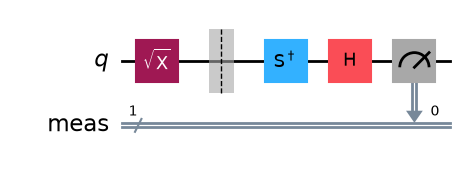

In [4]:
def build_circuit(name, gates, basis="Z"):
    qubits = QuantumRegister(1, name="q")
    bits = ClassicalRegister(1, name="meas")
    circuit = QuantumCircuit(qubits, bits, name=name)
    for k, gate in enumerate(gates):
        if k > 0:
            circuit.barrier()
        getattr(circuit, gate)(qubits[0])
    if basis == "Y":
        circuit.barrier()
        circuit.sdg(qubits[0])        # change of basis: S-dagger, then H
        circuit.h(qubits[0])
    circuit.measure(qubits, bits)
    return circuit


circuits = {
    "H": build_circuit("H", ["h"]),
    "SX": build_circuit("SX", ["sx"]),
    "H H": build_circuit("H H", ["h", "h"]),
    "SX SX": build_circuit("SX SX", ["sx", "sx"]),
    "H, Y basis": build_circuit("H, Y basis", ["h"], basis="Y"),
    "SX, Y basis": build_circuit("SX, Y basis", ["sx"], basis="Y"),
}
circuits["SX, Y basis"].draw("mpl")

The exact probabilities come from `Statevector`:

In [5]:
def show(z):
    """Format one amplitude compactly: 0.707, -0.707i, 0.5+0.5i."""
    re, im = round(z.real, 3) + 0, round(z.imag, 3) + 0   # + 0 turns -0.0 into 0.0
    if im == 0:
        return f"{re:g}"
    if re == 0:
        return f"{im:g}i"
    return f"{re:g}{im:+g}i"


ideal_p0 = {}
for name, circuit in circuits.items():
    state = Statevector(circuit.remove_final_measurements(inplace=False))
    ideal_p0[name] = state.probabilities()[0]
    amplitudes = "(" + ", ".join(show(z) for z in state.data) + ")"
    print(f"  {name:12s} amplitudes {amplitudes:20s}  P(0) = {ideal_p0[name]:.3f}")

  H            amplitudes (0.707, 0.707)        P(0) = 0.500
  SX           amplitudes (0.5+0.5i, 0.5-0.5i)  P(0) = 0.500
  H H          amplitudes (1, 0)                P(0) = 1.000
  SX SX        amplitudes (0, 1)                P(0) = 0.000
  H, Y basis   amplitudes (0.5-0.5i, 0.5+0.5i)  P(0) = 0.500
  SX, Y basis  amplitudes (0, 0.707+0.707i)     P(0) = 0.000


### Execution

The transpiler rewrites each gate into the backend's native gates. The
printout lists the gates of each transpiled circuit. On Aer the transpiler
merges the $S^\dagger$ and $H$ of the change of basis into one `u2` gate, a
general one-qubit gate given by two angles. On IBM hardware $H$ is not native
and becomes a short sequence of native gates, while `sx` is native.

In [6]:
isa_circuits = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    isa_circuits[target.label] = {k: pass_manager.run(c) for k, c in circuits.items()}
    print(target.label)
    for name, isa in isa_circuits[target.label].items():
        print(f"  {name:12s} {dict(isa.count_ops())}")

pubs = {
    label: [(isa,) for isa in group.values()]
    for label, group in isa_circuits.items()
}

results = {}
for target in targets:
    job = target.sampler.run(pubs[target.label], shots=SETTINGS.shots)
    # None if a hardware job failed or you stopped waiting.
    results[target.label] = target.wait(job)

aer
  H            {'h': 1, 'measure': 1}
  SX           {'sx': 1, 'measure': 1}
  H H          {'h': 2, 'barrier': 1, 'measure': 1}
  SX SX        {'sx': 2, 'barrier': 1, 'measure': 1}
  H, Y basis   {'h': 1, 'barrier': 1, 'u2': 1, 'measure': 1}
  SX, Y basis  {'sx': 1, 'barrier': 1, 'u2': 1, 'measure': 1}


### Analysis

In [7]:
for label, result in results.items():
    if result is None:
        continue
    print(f"{label}, {SETTINGS.shots} shots:")
    for name, pub_result in zip(circuits, result):
        counts = pub_result.data.meas.get_counts()
        p0 = counts.get("0", 0) / SETTINGS.shots
        exact = ideal_p0[name]
        counts_text = str(dict(sorted(counts.items())))
        probabilities = f"P(0) = {p0:.3f}   exact = {exact:.3f}"
        print(f"  {name:12s} counts {counts_text:22s}  {probabilities}")

aer, 4096 shots:
  H            counts {'0': 2002, '1': 2094}  P(0) = 0.489   exact = 0.500
  SX           counts {'0': 2028, '1': 2068}  P(0) = 0.495   exact = 0.500
  H H          counts {'0': 4096}             P(0) = 1.000   exact = 1.000
  SX SX        counts {'1': 4096}             P(0) = 0.000   exact = 0.000
  H, Y basis   counts {'0': 2049, '1': 2047}  P(0) = 0.500   exact = 0.500
  SX, Y basis  counts {'1': 4096}             P(0) = 0.000   exact = 0.000


$H$ and $\sqrt{X}$ each give about 50/50 in the Z basis. The measured $P(0)$
is not exactly 0.500, because each value comes from 4096 random shots. For
$p = 0.5$ the scatter is $\sqrt{0.5 \times 0.5/4096} \approx 0.008$, so by the
scatter rule of Notebook 00 most runs land between about 0.484 and 0.516, and a
value two to three scatters away, such as 0.48, turns up by chance now and
then. $HH$ returns 0 and $\sqrt{X}\sqrt{X}$ returns 1 on every shot, as
Examples 2 and 3 predicted; on the simulator these have no scatter at all,
because their ideal probabilities are exactly 0 and 1. In the Y basis,
$\sqrt{X}$ returns 1 on every shot while $H$ stays near 50/50: one measurement
separates the two one-gate states.

## Exercises

1. Predict the Z-basis probabilities after applying $\sqrt{X}$ three times to
   $|0\rangle$, and after four times.
2. Use interference, amplitude by amplitude, to compute $HXH|0\rangle$.
3. Predict the X-basis and Y-basis results for $|{+i}\rangle$. Does either
   basis tell $|+\rangle$ from $|{+i}\rangle$ on every shot? Could any
   measurement basis?
4. Design a measurement in the basis $\{|s\rangle, |s_\perp\rangle\}$ with
   $|s\rangle = \cos\tfrac{\pi}{8}|0\rangle + \sin\tfrac{\pi}{8}|1\rangle$:
   build the matrix $V_s^\dagger$ as in Notebook 05 and add it to a circuit
   as a `UnitaryGate` (Notebook 05) before the measurement. What probability
   of 0 do you predict for the input $|0\rangle$? Run it on Aer.
5. Use Notebook 01: $X$ flips the result of a Z-basis measurement. Which gate
   flips the result of an X-basis measurement? Check with $|+\rangle$.
6. True or false: $\sqrt{X}$ acts like a coin that applies NOT half the time.
   Give the reason.
7. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   notebook. How far from 1.000 is $P(0)$ for $HH$, and from 0.000 for
   $\sqrt{X}\sqrt{X}$? Compare the transpiled gate counts of the two circuits:
   does the one with more native gates do worse?
8. (hardware) For "SX, Y basis", is the hardware $P(0)$ larger than 0.000 by
   more than the scatter rule of Notebook 00 allows? Which steps of the
   circuit could contribute to the error?

## What you can now do

1. Predict the result of $HH$ and $\sqrt{X}\sqrt{X}$ by adding amplitudes,
   outcome by outcome, before squaring.
2. Explain that $H|0\rangle$ and $\sqrt{X}|0\rangle$ are different states,
   $|+\rangle$ and $|{-i}\rangle$ up to a global phase, with identical Z-basis
   counts.
3. Measure in the X basis ($H$, then measure) or the Y basis ($S^\dagger$,
   then $H$, then measure), and in general in any basis with $V_s^\dagger$.

## Solutions

**Check, square root of NOT.** $\sqrt{X}|1\rangle$ is the second column,
$\tfrac12\big((1-i)|0\rangle + (1+i)|1\rangle\big)$. Each amplitude has
$|{\cdot}|^2 = 2/4$, so the probabilities are $\tfrac12$ and $\tfrac12$.

**Check, interference.** $H|0\rangle = |+\rangle$. $X$ swaps the amplitudes of
$|0\rangle$ and $|1\rangle$, which are equal, so $X|+\rangle = |+\rangle$. The
last $H$ gives $H|+\rangle = |0\rangle$ by Example 2. Every shot returns 0.

**Check, measurement basis.** The X basis: $|+\rangle$ gives 0 and $|-\rangle$
gives 1 on every shot. In the Y basis both give 50/50, since
$|\langle{+i}|\pm\rangle|^2 = \tfrac12$.

**Exercise 1.** Three applications: $\sqrt{X}^3 = X\sqrt{X}$, so the state is
$X$ applied to $\sqrt{X}|0\rangle$, which swaps its two amplitudes; both have
modulus squared $\tfrac12$, so the counts are 50/50. Four applications:
$\sqrt{X}^4 = X^2 = I$, so the qubit returns to $|0\rangle$ and every shot is 0.

**Exercise 2.** $H|0\rangle = \tfrac{1}{\sqrt2}(|0\rangle + |1\rangle)$, and
$X$ swaps the two parts, giving the same state. Apply the last $H$ to each
part: the $|0\rangle$ part contributes $\tfrac12$ to outcome 0 and $\tfrac12$
to outcome 1; the $|1\rangle$ part contributes $\tfrac12$ to outcome 0 and
$-\tfrac12$ to outcome 1. Add: outcome 0 gets 1, outcome 1 gets 0. So
$HXH|0\rangle = |0\rangle$. (In fact $HXH = Z$.)

**Exercise 3.** X basis: $|\langle +|{+i}\rangle|^2 = \big|\tfrac{1+i}{2}\big|^2 = \tfrac12$,
so 50/50. Y basis: $|{+i}\rangle$ is one of the basis states, so every shot
returns 0. Neither basis separates $|+\rangle$ from $|{+i}\rangle$ on every
shot: in the X basis $|+\rangle$ always gives 0 but $|{+i}\rangle$ gives 0
half the time, and in the Y basis the roles swap. No measurement basis
$\{|s\rangle, |s_\perp\rangle\}$ can. For the results to be certain and
different, one state must have overlap 1 with $|s\rangle$ and the other overlap
1 with $|s_\perp\rangle$, so the two states would be $|s\rangle$ and
$|s_\perp\rangle$ up to global phases, and therefore orthogonal. But
$|\langle +|{+i}\rangle|^2 = \tfrac12$, not 0. Only orthogonal states can be
told apart on every shot.

**Exercise 4.** The probability of 0 is the overlap
$|\langle s|0\rangle|^2 = \cos^2\tfrac{\pi}{8} \approx 0.854$. The matrix
$V_s$ has $|s\rangle$ as its first column and
$|s_\perp\rangle = (-\bar\beta, \bar\alpha)^T$ as its second (Notebook 05), and
$V_s^\dagger$ is its conjugate transpose. In code, using the Setup cell's
imports:

```python
from qiskit.circuit.library import UnitaryGate


def prepare_matrix(state):
    """V_s = |s><0| + |s_perp><1|: columns |s> and |s_perp> (Notebook 05)."""
    alpha, beta = state
    s_perp = np.array([-np.conj(beta), np.conj(alpha)])
    return np.column_stack([state, s_perp])


s = np.array([np.cos(np.pi / 8), np.sin(np.pi / 8)])
qubits = QuantumRegister(1, name="q")
bits = ClassicalRegister(1, name="meas")
circuit = QuantumCircuit(qubits, bits)
circuit.append(UnitaryGate(prepare_matrix(s).conj().T), qubits)
circuit.measure(qubits, bits)
```

Run `circuit` with the Execution cell's pattern (one PUB, `(isa,)`). On Aer
the fraction of 0s lands near 0.854; the scatter is
$\sqrt{0.854 \times 0.146/4096} \approx 0.006$.

**Exercise 5.** $Z$: since $Z|+\rangle = |-\rangle$ and $Z|-\rangle = |+\rangle$,
it swaps the two X-basis states the way $X$ swaps $|0\rangle$ and $|1\rangle$.
Check: $Z|+\rangle = \tfrac{1}{\sqrt2}(|0\rangle - |1\rangle) = |-\rangle$, so
an X-basis measurement of $Z|+\rangle$ returns 1 on every shot instead of 0.

**Exercise 6.** False. A coin that applies NOT half the time, applied twice,
would leave the qubit at 0 or 1 with probability $\tfrac12$ each, so the counts
would be 50/50. Example 3 and the experiment show that $\sqrt{X}\sqrt{X}$
returns 1 on every shot. The amplitudes interfere; coin probabilities cannot.

**Exercise 7.** Expect both values a few tenths of a percent to a few percent
from ideal; the size depends on that day's calibration. The scatter for
$p = 0.99$ and $N = 4096$ is about 0.002, so by the scatter rule of
Notebook 00 a gap of more than about 0.006 is hardware error, not chance.
$HH$ usually has more native gates than $\sqrt{X}\sqrt{X}$, because each $H$
becomes several native gates while `sx` is native, and more gates usually
means a slightly larger error, though readout error often dominates for such
short circuits.

**Exercise 8.** The ideal $P(0)$ is 0, so any 0s are errors. With a measured
$p$ of, say, 0.02, the scatter is about $\sqrt{0.02 \times 0.98/4096} \approx 0.002$,
so the value is about ten scatters above 0 and, by the scatter rule of
Notebook 00, a real error. It can come from the $\sqrt{X}$ gate, from the
$S^\dagger$ and $H$ of the change of basis, and from the readout; Notebook 00
explains why readout errors lean toward 0, which here pushes $P(0)$ up.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| square root of NOT, $\sqrt{X}$ (SX) | $\frac{1+i}{2}I + \frac{1-i}{2}X$; applied twice it gives $X$ |
| interference | the adding of amplitudes from different parts of a state to the same outcome, before squaring; they can cancel or reinforce |
| measurement basis | a pair of orthogonal states $\{\lvert s\rangle, \lvert s_\perp\rangle\}$ that a measurement tells apart, returning 0 and 1 |
| change of basis | applying $V_s^\dagger$ before a Z-basis measurement, so that it measures in the basis $\{\lvert s\rangle, \lvert s_\perp\rangle\}$ |
| X basis | $\{\lvert +\rangle, \lvert -\rangle\}$; measured by $H$, then a Z-basis measurement |
| Y basis | $\{\lvert {+i}\rangle, \lvert {-i}\rangle\}$; measured by $S^\dagger$, then $H$, then a Z-basis measurement |